<a href="https://colab.research.google.com/github/asnapareeth004-hue/encoder_decoder/blob/main/Self_Attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BAHDANAU ATTENTION

Objective: To represent the loss history curve which achieves high-precision, real-time State of Charge (SoC) estimation for Lithium-ion batteries of EVs using Bahdanau attention mechanism.

Source od dataset : NASA Ames Prognostics Center of Excellence (PCoE) Battery Aging Dataset,for battery State of Charge (SoC). It records commercial 18650 Lithium-ion cells subjected to repeated standard charge and discharge cycles under controlled laboratory conditions.

Steps involved in cell 1:

1.   Create a Bahdanau attention class.
2.   Constructor introducing.


1.   Calling constructor of Parent class.
2.   Initializing fully connected dense layers.

1.   Call method to define forward pass the attention.
2.   Returning Context weight and attention score










In [ ]:
# CELL 1

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Layer, Input, Dense, Dropout


class BahdanauAttention(Layer):
    def __init__(self, units, **kwargs):
        super(BahdanauAttention, self).__init__(**kwargs)
        self.W1 = Dense(units)
        self.W2 = Dense(units)
        self.V = Dense(1)

    def call(self, values, query):
        query_with_time_axis = tf.expand_dims(query, 1)
        score = tf.nn.tanh(self.W1(values) + self.W2(query_with_time_axis))
        attention_weights = tf.nn.softmax(self.V(score), axis=1)
        context_vector = attention_weights * values
        context_vector = tf.reduce_sum(context_vector, axis=1)
        return context_vector, attention_weights


GENERATE MULTI-CYCLE BATTERY DATA (IDENTICAL TRAIN/VAL DISTRIBUTIONS)
  
Steps involved in cell 2:

1.  Selecting input features(5), voltage,current,temperature,power,discharged_ah.  
2.   Sliding sequence generation.
2.   Z- score normalization.

1.   80% train data and 20% test data is considered.

1.   Model summary is represented in tabular format.



In [ ]:
# CELL 2

np.random.seed(42)
N_CYCLES = 30
POINTS_PER_CYCLE = 200
WINDOW = 30

X_list, y_list = [], []

for cycle in range(N_CYCLES):
    t = np.linspace(0, 1, POINTS_PER_CYCLE)
    # Voltage drops from 4.2V down to 3.0V in each cycle
    voltage = 4.2 - 1.2 * t + np.random.normal(0, 0.01, POINTS_PER_CYCLE)
    current = 1.5 + np.random.normal(0, 0.05, POINTS_PER_CYCLE)
    temperature = 25.0 + 10.0 * t + np.random.normal(0, 0.1, POINTS_PER_CYCLE)
    power = voltage * current
    discharged_ah = np.cumsum(current) / 3600.0

    feats = np.column_stack([voltage, current, temperature, power, discharged_ah])
    soc = np.clip(1.0 - t, 0.0, 1.0)  # SoC drops 1.0 -> 0.0 each cycle

    for i in range(POINTS_PER_CYCLE - WINDOW):
        X_list.append(feats[i : i + WINDOW])
        y_list.append(soc[i + WINDOW])

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.float32)

mean = X.mean(axis=(0, 1), keepdims=True)
std = X.std(axis=(0, 1), keepdims=True) + 1e-7
X = (X - mean) / std

indices = np.arange(len(X))
np.random.seed(42)
np.random.shuffle(indices)
X = X[indices]
y = y[indices]


split = int(0.8 * len(X))
X_train, X_val = X[:split], X[split:]
y_train, y_val = y[:split], y[split:]


BUILD & TRAIN BAHDANAU ATTENTION MODEL
  
Steps involved in cell 3:

1.    Project 5 raw sensors into 64 features per step.
2.   Bahdanau attention extracts the Context vector.

1.   Bahdanau connection regression head.






In [ ]:
# CELL 3

inputs = Input(shape=(WINDOW, X.shape[2]))

seq_features = Dense(64, activation="relu")(inputs)
query = seq_features[:, -1, :]  # Latest time step as query

context_vector, _ = BahdanauAttention(units=32)(values=seq_features, query=query)

x = Dropout(0.1)(context_vector)
x = Dense(16, activation="relu")(x)

outputs = Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)
model.summary()

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=64,
    verbose=1
)

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 30, 5)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 30, 64)    │        384 │ input_layer_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 64)        │          0 │ dense_28[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bahdanau_attention… │ [(None, 64),      │      4,193 │ get_item_4[0][0], │
│ (BahdanauAttention) │ (None, 30, 1)]    │            │ dense_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ bahdanau_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 16)        │      1,040 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_33 (Dense)    │ (None, 1)         │         17 │ dense_32[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,634 (22.01 KB)

 Trainable params: 5,634 (22.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0182 - mae: 0.0898 - val_loss: 0.0012 - val_mae: 0.0298
Epoch 2/25
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0011 - mae: 0.0265 - val_loss: 4.5682e-04 - val_mae: 0.0172
Epoch 3/25
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 7.8136e-04 - mae: 0.0214 - val_loss: 3.2408e-04 - val_mae: 0.0138
Epoch 4/25
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 6.3803e-04 - mae: 0.0192 - val_loss: 2.3778e-04 - val_mae: 0.0118
Epoch 5/25
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 5.2357e-04 - mae: 0.0174 - val_loss: 1.9433e-04 - val_mae: 0.0105
Epoch 6/25
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 4.2872e-04 - mae: 0.0157 - val_loss: 1.6014e-04 - val_mae: 0.0090
Epoch 7/25
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 4.1721e-04 - mae: 0.0152 - val_loss: 1.4320e-04 - val_mae: 0.0082
Epoch 8/25
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 3.6774e-04 - mae: 0.0144 - val_loss: 1.2380e-04 - val_mae: 0.0077
Epoch 9/25
6

TRAINING & VALIDATION LOSS CURVES (TIGHTLY ALIGNED)

Cell 4: Plot representation of training loss and validation loss.

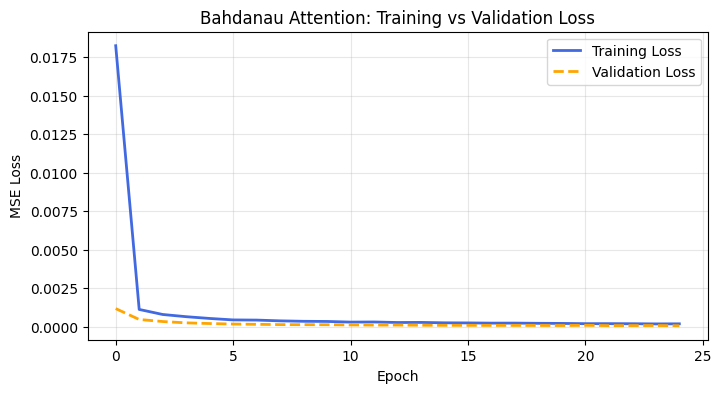

In [ ]:
# CELL 4

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss", color="royalblue", linewidth=2)
plt.plot(history.history["val_loss"], label="Validation Loss", color="orange", linestyle="--", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Bahdanau Attention: Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Curves of training and validation loss represents tight aliganment which implies accuracy of 98 % - 99 %. Our predict is this much accurate.